# 不同主频四组模型对比重绘

地形与低速层四组对照，默认读取15Hz和30Hz，统一绘图方法，按主频分别输出。


## 输入与输出约定

这里的代码只读输入，不重跑模拟，不修改原始SEG-Y/VTS。路径可以是绝对路径；相对路径以项目外层工作区为基准。生成的图件、CSV、缓存及执行副本统一放入外层`out`的子目录。

如果输入不是默认文件夹结构，可在配置中为每个算例单独填写`record_files`、`geometry_csv`、`model_vts`、`snapshot_index_csv`和`snapshot_dir`，详见同目录README。源码中的Notebook不保存运行输出；需要保留执行结果时请另存到`out`。


In [3]:
import sys, json
from pathlib import Path
sys.dont_write_bytecode = True

# 如果Notebook从其他位置启动，可在这里指定仓库根目录。
REPOSITORY_ROOT = None
if REPOSITORY_ROOT is None:
    candidates = [p for q in [Path.cwd(), *Path.cwd().parents]
                  for p in [q, q / "SeisWaveLab_Curvilinear"]
                  if (p / "tools/seismic_plotting/seisplot/core.py").is_file()]
    if not candidates:
        raise FileNotFoundError("请将REPOSITORY_ROOT设为Git仓库根目录")
    REPOSITORY_ROOT = candidates[0].resolve()
else:
    REPOSITORY_ROOT = Path(REPOSITORY_ROOT).expanduser().resolve()
WORKSPACE = REPOSITORY_ROOT.parent
TOOL_DIR = REPOSITORY_ROOT / "tools/seismic_plotting"
sys.path.insert(0, str(TOOL_DIR))
from seisplot.core import load_config, gallery
SHOW_INLINE = True


In [4]:
from seisplot.four_case import FourCaseStudy
CONFIG = load_config(TOOL_DIR / "examples/four_frequency.json")

# 主要修改这里的输入、输出路径。可新增其他主频，或只保留一个。
INPUT_DATASETS = {
    "15Hz": WORKSPACE / "out/jingbian_15Hz_2m",
    "30Hz": WORKSPACE / "out/jingbian_30Hz_2m",
}
OUTPUT_DIR = WORKSPACE / "out/replots/four_frequency"
from copy import deepcopy
template = CONFIG["datasets"][0]
CONFIG["datasets"] = []
for label, root in INPUT_DATASETS.items():
    dataset = deepcopy(template)
    dataset.update(label=label, root=str(root))
    CONFIG["datasets"].append(dataset)
CONFIG["output_dir"] = str(OUTPUT_DIR)
CONFIG["snapshots"]["times_s"] = [0.5, 1.0, 2.0]  # None表示全部已导出时刻
RUN_MODELS = True
RUN_WAVEFIELDS = True


## 1. 检查数据

道数、采样点数和dt从文件读取，不固定为250道或6001点。


In [5]:
study = FourCaseStudy(CONFIG)
inventory = study.inspect()
print(json.dumps(inventory, ensure_ascii=False, indent=2))


[
  {
    "dataset": "15Hz",
    "case": "M00",
    "component": "Vx",
    "traces": 250,
    "samples": 6001,
    "dt_s": 0.0005,
    "duration_s": 3.0,
    "input_file": "D:\\Code\\visual_code\\Cmake_project\\CMake_pro_CUDA\\SeisWaveLab_Curvilinear_Workspace\\out\\jingbian_15Hz_2m\\01_M00_flat_no_lvl\\records\\Vx.sgy"
  },
  {
    "dataset": "15Hz",
    "case": "M00",
    "component": "Vz",
    "traces": 250,
    "samples": 6001,
    "dt_s": 0.0005,
    "duration_s": 3.0,
    "input_file": "D:\\Code\\visual_code\\Cmake_project\\CMake_pro_CUDA\\SeisWaveLab_Curvilinear_Workspace\\out\\jingbian_15Hz_2m\\01_M00_flat_no_lvl\\records\\Vz.sgy"
  },
  {
    "dataset": "15Hz",
    "case": "M10",
    "component": "Vx",
    "traces": 250,
    "samples": 6001,
    "dt_s": 0.0005,
    "duration_s": 3.0,
    "input_file": "D:\\Code\\visual_code\\Cmake_project\\CMake_pro_CUDA\\SeisWaveLab_Curvilinear_Workspace\\out\\jingbian_15Hz_2m\\02_M10_terrain_no_lvl\\records\\Vx.sgy"
  },
  {
    "dataset": "

## 2. 原始、整体RMS与AGC记录

灰度与显示插值只影响图面。定量指标始终使用原始记录。


In [6]:
study.plot_records()


[WindowsPath('D:/Code/visual_code/Cmake_project/CMake_pro_CUDA/SeisWaveLab_Curvilinear_Workspace/out/replots/four_frequency/figures/15Hz_gathers_Vx_raw.png'),
 WindowsPath('D:/Code/visual_code/Cmake_project/CMake_pro_CUDA/SeisWaveLab_Curvilinear_Workspace/out/replots/four_frequency/figures/15Hz_gathers_Vx_raw.pdf'),
 WindowsPath('D:/Code/visual_code/Cmake_project/CMake_pro_CUDA/SeisWaveLab_Curvilinear_Workspace/out/replots/four_frequency/figures/15Hz_gathers_Vx_rms.png'),
 WindowsPath('D:/Code/visual_code/Cmake_project/CMake_pro_CUDA/SeisWaveLab_Curvilinear_Workspace/out/replots/four_frequency/figures/15Hz_gathers_Vx_rms.pdf'),
 WindowsPath('D:/Code/visual_code/Cmake_project/CMake_pro_CUDA/SeisWaveLab_Curvilinear_Workspace/out/replots/four_frequency/figures/15Hz_gathers_Vx_agc.png'),
 WindowsPath('D:/Code/visual_code/Cmake_project/CMake_pro_CUDA/SeisWaveLab_Curvilinear_Workspace/out/replots/four_frequency/figures/15Hz_gathers_Vx_agc.pdf'),
 WindowsPath('D:/Code/visual_code/Cmake_projec

## 3. 全域与浅层速度模型

全域读取实际保存的物理坐标。浅层η坐标来自网格行号乘间距，不将其冒充地形。


In [7]:
if RUN_MODELS:
    study.plot_models()
    study.plot_models(shallow=True)


## 4. 同一时刻波场

保留detail_symlog，同一数据集全部模型和所选时刻默认共用物理幅度尺度。可在配置中指定空间裁切。


In [8]:
if RUN_WAVEFIELDS:
    study.plot_wavefields()


## 5. 原始记录定量对比

包含矢量RMS、近炮晚时平方速度积分占比、时间响应、Welch频谱、镜像相关及偏移距分布。平方速度积分不是总物理能量，也不是SNR。


In [9]:
study.plot_terrain_profile()
study.plot_metrics()
study.plot_frequency_compare()


[WindowsPath('D:/Code/visual_code/Cmake_project/CMake_pro_CUDA/SeisWaveLab_Curvilinear_Workspace/out/replots/four_frequency/figures/source_frequency_metrics.png'),
 WindowsPath('D:/Code/visual_code/Cmake_project/CMake_pro_CUDA/SeisWaveLab_Curvilinear_Workspace/out/replots/four_frequency/figures/source_frequency_metrics.pdf')]

## 6. 反射参考与几何对齐

红色、橙色表示R1/R2参考。平地使用分层射线参数，起伏模型仅加几何近似校正；这些曲线不是自动反射拾取。更换模型后必须修改参考层界和速度。


In [10]:
study.plot_reflections()


[WindowsPath('D:/Code/visual_code/Cmake_project/CMake_pro_CUDA/SeisWaveLab_Curvilinear_Workspace/out/replots/four_frequency/figures/15Hz_reflection_windows_agc.png'),
 WindowsPath('D:/Code/visual_code/Cmake_project/CMake_pro_CUDA/SeisWaveLab_Curvilinear_Workspace/out/replots/four_frequency/figures/15Hz_reflection_windows_agc.pdf'),
 WindowsPath('D:/Code/visual_code/Cmake_project/CMake_pro_CUDA/SeisWaveLab_Curvilinear_Workspace/out/replots/four_frequency/figures/15Hz_reflection_alignment.png'),
 WindowsPath('D:/Code/visual_code/Cmake_project/CMake_pro_CUDA/SeisWaveLab_Curvilinear_Workspace/out/replots/four_frequency/figures/15Hz_reflection_alignment.pdf'),
 WindowsPath('D:/Code/visual_code/Cmake_project/CMake_pro_CUDA/SeisWaveLab_Curvilinear_Workspace/out/replots/four_frequency/figures/30Hz_reflection_windows_agc.png'),
 WindowsPath('D:/Code/visual_code/Cmake_project/CMake_pro_CUDA/SeisWaveLab_Curvilinear_Workspace/out/replots/four_frequency/figures/30Hz_reflection_windows_agc.pdf'),
 W

输出目录： D:\Code\visual_code\Cmake_project\CMake_pro_CUDA\SeisWaveLab_Curvilinear_Workspace\out\replots\four_frequency


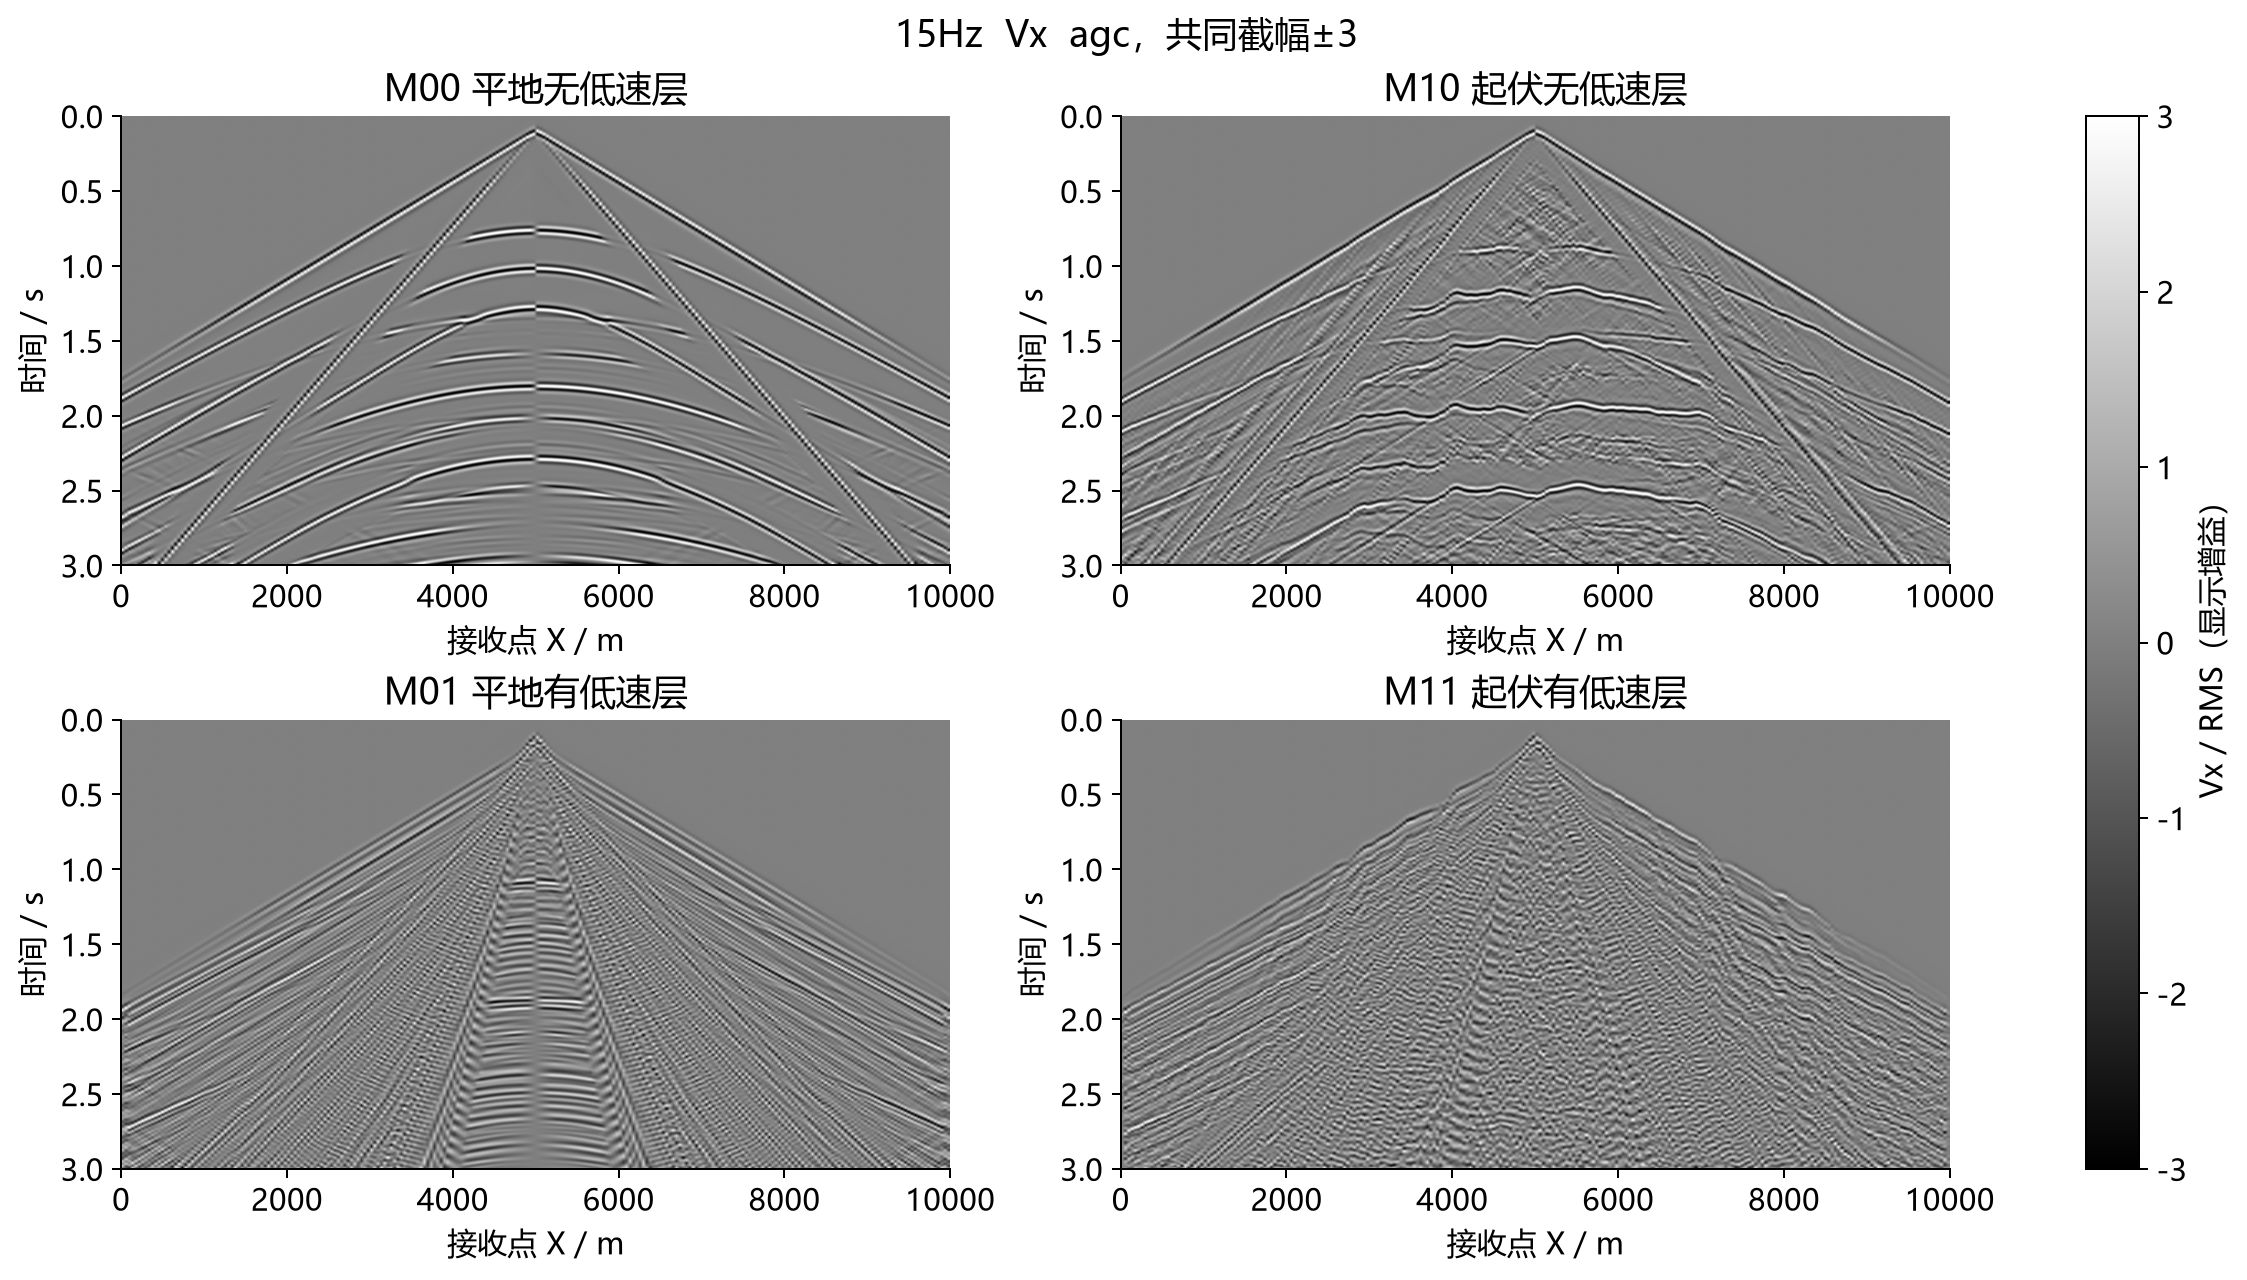

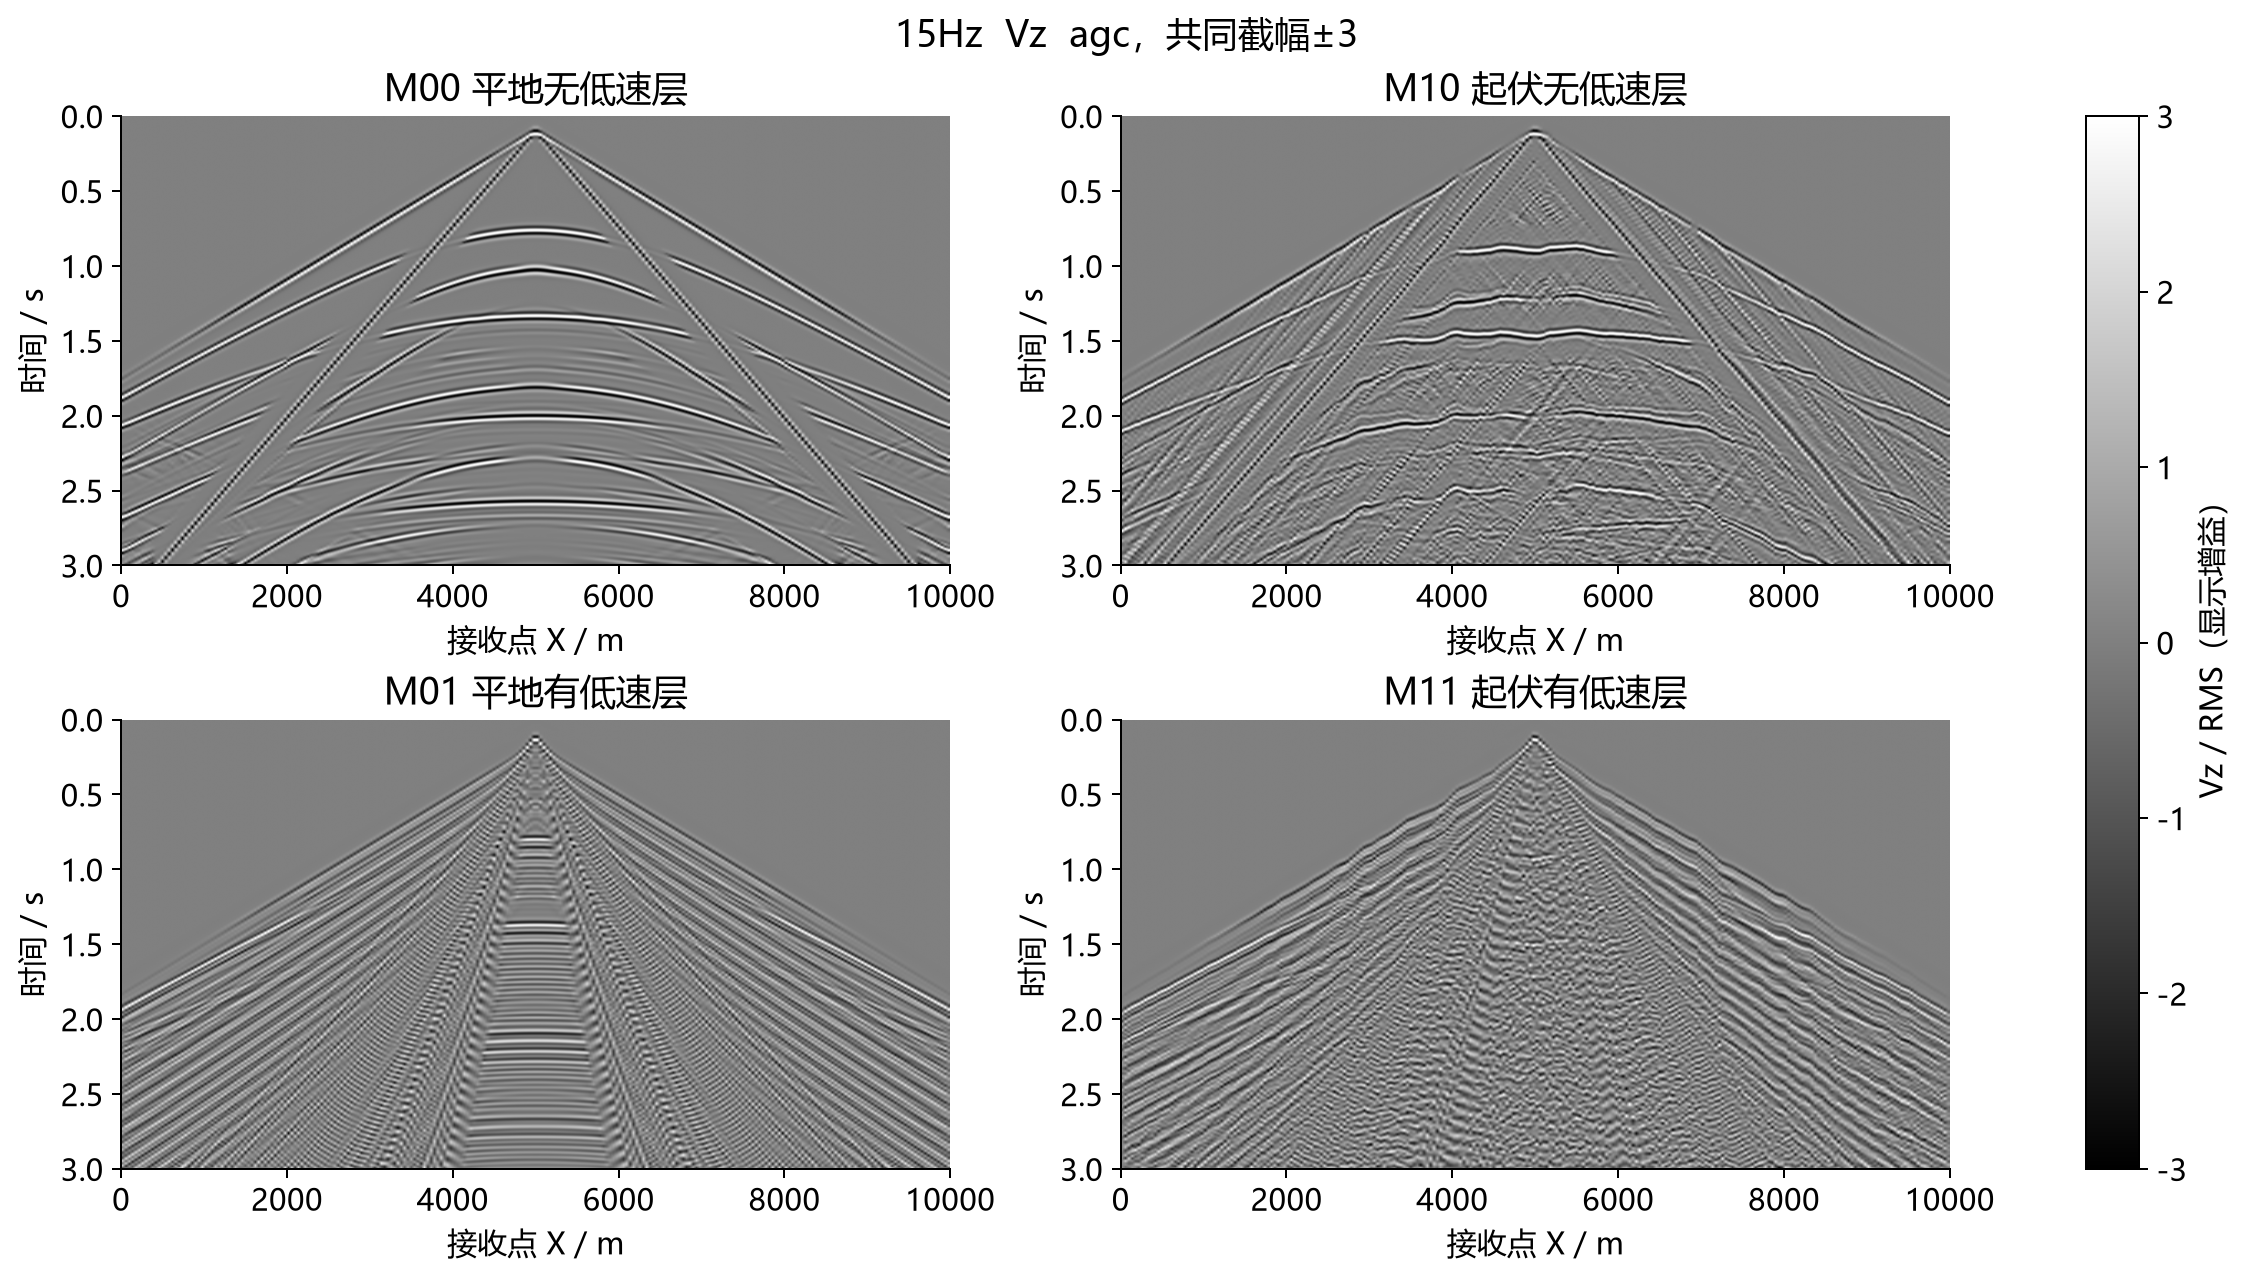

In [11]:
print("输出目录：", study.out)
if SHOW_INLINE:
    gallery(study.out, "*gathers*agc.png", limit=2)
